In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [2]:
parton_phase_m_m5 = np.loadtxt("parton_phase_m_m5.csv", delimiter=",")
parton_phase_m_m3 = np.loadtxt("parton_phase_m_m3.csv", delimiter=",")
parton_phase_m_m2 = np.loadtxt("parton_phase_m_m2.csv", delimiter=",")
parton_phase_m_m4p5 = np.loadtxt("parton_phase_m_m4p5.csv", delimiter=",")

double_phase_m_m5 = np.loadtxt("double_phase_m_m5.csv", delimiter=",")
double_phase_m_m3 = np.loadtxt("double_phase_m_m3.csv", delimiter=",")
double_phase_m_m2 = np.loadtxt("double_phase_m_m2.csv", delimiter=",")
double_phase_m_m4p5 = np.loadtxt("double_phase_m_m4p5.csv", delimiter=",")

In [3]:
g_values = np.linspace(0.0, 1.0, 11)

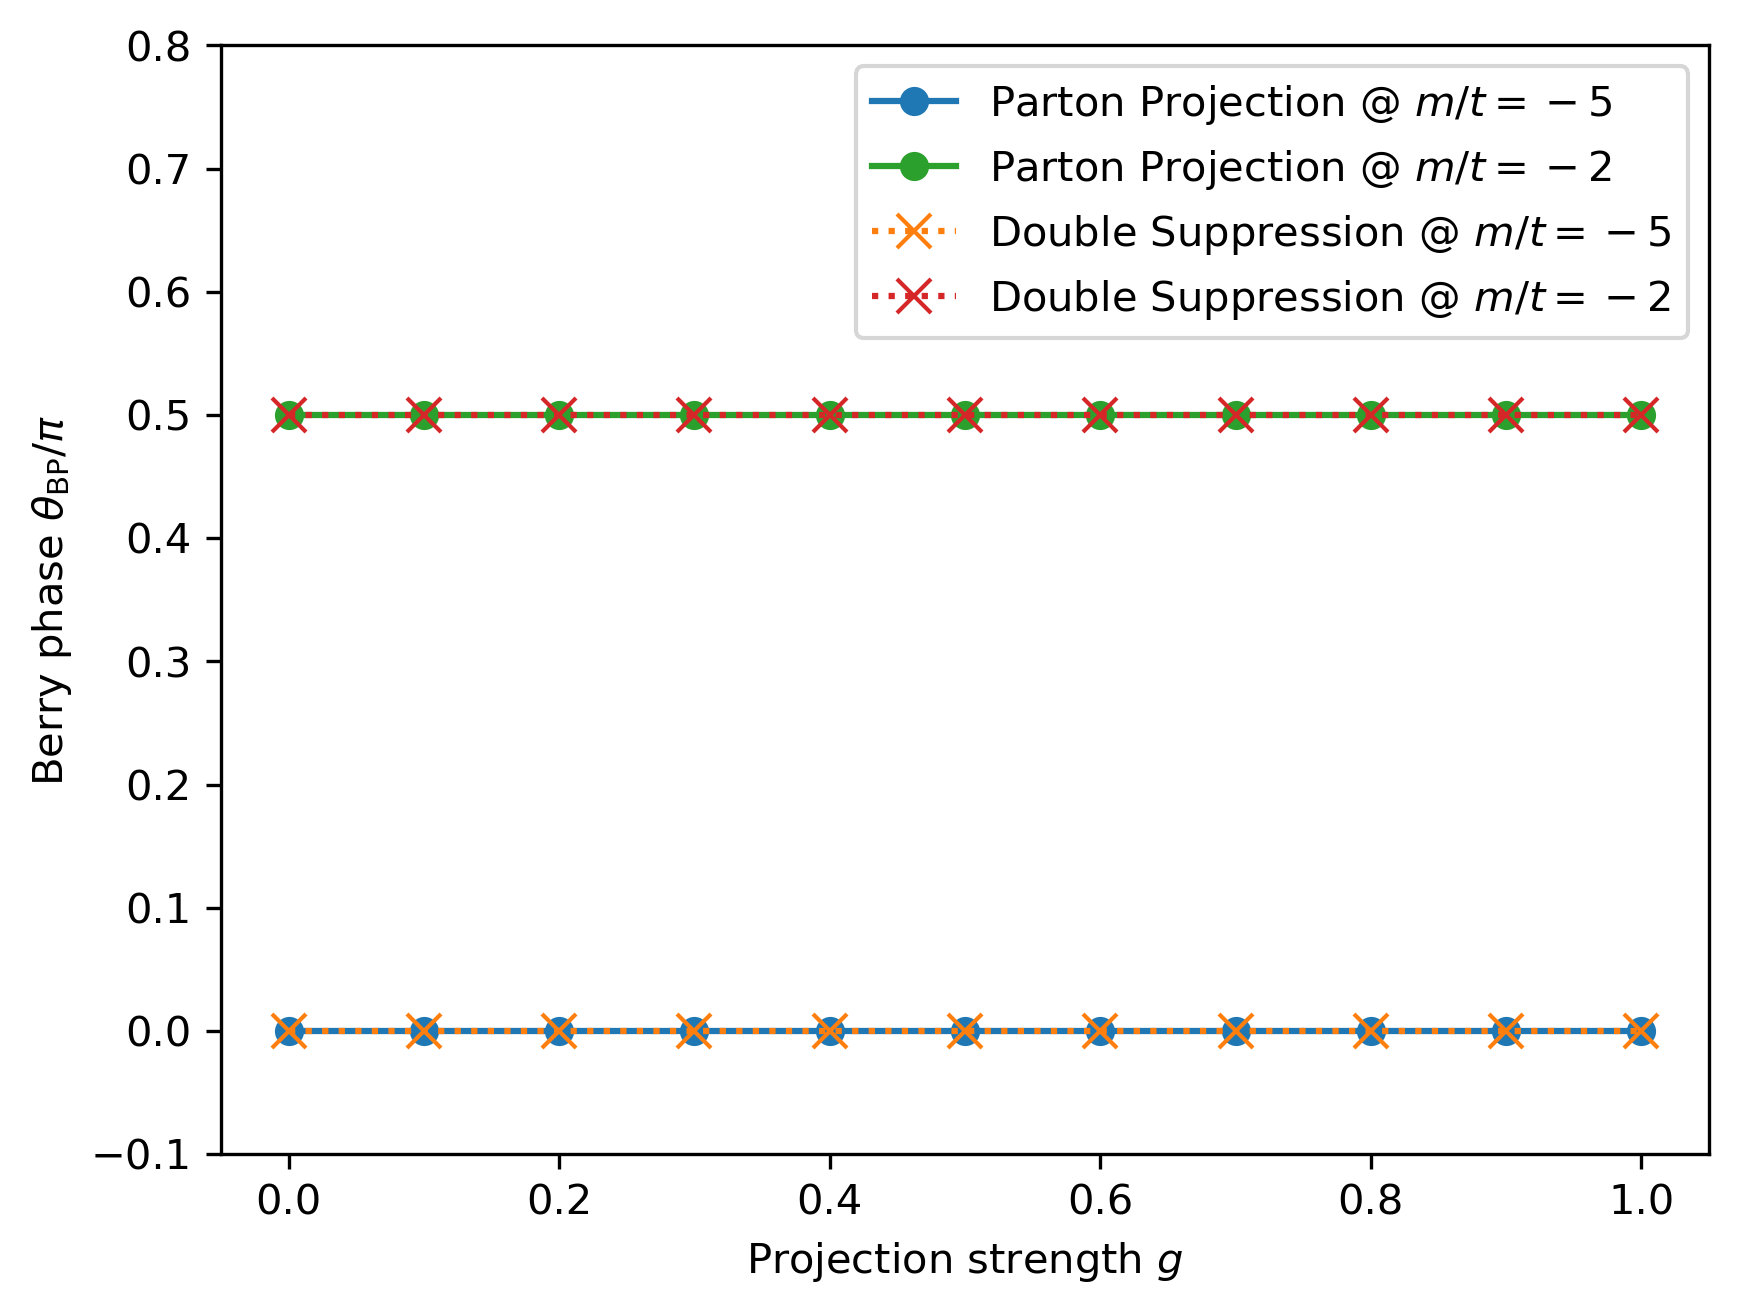

In [24]:
plt.figure(dpi = 300)
plt.plot(g_values, abs(parton_phase_m_m5), label = r"Parton Projection @ $m/t = -5$", marker = "o", color = "tab:blue")
# plt.plot(g_values, parton_phase_m_m4p5, label = r"Parton Projection @ $m = -4.5$", marker = "o")
# plt.plot(g_values, parton_phase_m_m3, label = r"Parton Projection @ $m = -3$", marker = "o")
plt.plot(g_values, abs(parton_phase_m_m2), label = r"Parton Projection @ $m/t = -2$", marker = "o", color = "tab:green")


plt.plot(g_values, abs(double_phase_m_m5), label = r"Double Suppression @ $m/t = -5$", marker = "x", markersize = 8,
         linestyle = "dotted", color = "tab:orange")
# plt.plot(g_values, double_phase_m_m4p5, label = r"Double Projection @ $m = -4.5$", marker = "s")
# plt.plot(g_values, double_phase_m_m3, label = r"Double Projection @ $m = -3$", marker = "s")
plt.plot(g_values, abs(double_phase_m_m2), label = r"Double Suppression @ $m/t = -2$", marker = "x", markersize = 8,
         linestyle = "dotted", color = "tab:red")
plt.xlabel(r"Projection strength $g$")
plt.ylabel(r"Berry phase $\theta_{\text{BP}}/\pi$")
plt.ylim(-0.1,0.8)
plt.legend()
plt.show()

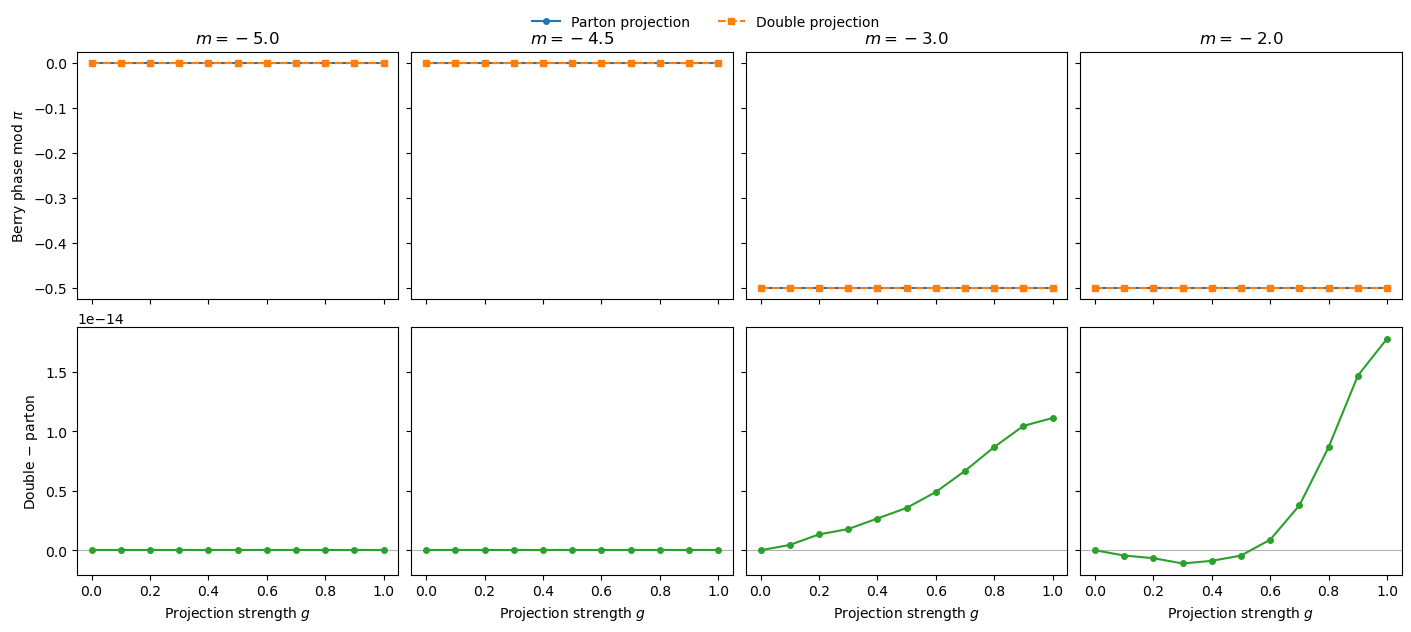

In [10]:
datasets = [
    (-5.0, parton_phase_m_m5,   double_phase_m_m5),
    (-4.5, parton_phase_m_m4p5, double_phase_m_m4p5),
    (-3.0, parton_phase_m_m3,   double_phase_m_m3),
    (-2.0, parton_phase_m_m2,   double_phase_m_m2),
]

fig, axes = plt.subplots(
    2, 4 ,   figsize=(14, 6),
    sharex=True,
    sharey="row",
    layout="constrained",
)

for j, (m, parton, double) in enumerate(datasets):
    ax = axes[0, j]
    ax.plot(
        g_values, parton,
        color="C0", marker="o", markersize=4,
        label="Parton projection",
    )
    ax.plot(
        g_values, double,
        color="C1", marker="s", markersize=4,
        linestyle="--", label="Double projection",
    )
    ax.set_title(rf"$m = {m}$")

    # Wrapped phase difference in [-pi/2, pi/2)
    difference = (double - parton + np.pi / 2) % np.pi - np.pi / 2

    ax_diff = axes[1, j]
    ax_diff.axhline(0, color="0.7", linewidth=0.8)
    ax_diff.plot(
        g_values, difference,
        color="C2", marker="o", markersize=4,
    )
    ax_diff.set_xlabel(r"Projection strength $g$")

axes[0, 0].set_ylabel(r"Berry phase mod $\pi$")
axes[1, 0].set_ylabel(r"Double $-$ parton")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=2,
    frameon=False,
)


plt.show()